# Student Performance — Exploratory Data Analysis
**AN-Najah National University** | Introduction to Data Science | April 12, 2026

## 0. Imports & Global Settings

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize']    = (10, 5)
plt.rcParams['axes.titlesize']    = 14
plt.rcParams['axes.labelsize']    = 12
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

## 1. Data Understanding

We start by loading the dataset and examining its **shape, data types, and basic statistics**
to understand what we're working with before any cleaning.

In [15]:
df = pd.read_csv('student_performance.csv')
print('Shape:', df.shape)
df.head(10)

Shape: (546, 10)


,age,study_hours,attendance_rate,parent_education,internet_access,sleep_hours,stress_level,engagement_score,final_grade,extra_notes
0,21,NaN,0.852781,NaN,Yes,8.186294,2.0,88.700319,60.579505,good
1,23,4.201040,0.521436,HS,Y,7.514911,9.0,36.344056,74.789189,NaN
2,21,3.929549,0.575569,NaN,N,6.969353,1.0,36.229529,45.755929,good
3,19,1.795490,0.871944,Bachelor,N,7.666824,1.0,29.792033,63.170932,NaN
4,20,10.198600,0.942683,High School,Yes,5.393588,3.0,37.757506,71.487670,good
5,22,6.995718,0.550009,HS,No,NaN,6.0,66.573875,69.359686,NaN
6,24,6.096673,0.564921,HS,N,4.642813,5.0,41.217497,NaN,poor
7,20,5.014652,0.878321,HS,No,4.334325,5.0,78.266902,70.456747,poor
8,22,6.789830,0.796206,HS,No,NaN,9.0,NaN,63.761565,NaN
9,23,4.575311,0.692988,High School,Yes,8.158249,9.0,43.485663,73.008140,poor


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 546 entries, 0 to 545
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               508 non-null    object 
 1   study_hours       487 non-null    float64
 2   attendance_rate   517 non-null    float64
 3   parent_education  511 non-null    object 
 4   internet_access   545 non-null    object 
 5   sleep_hours       466 non-null    float64
 6   stress_level      522 non-null    float64
 7   engagement_score  503 non-null    float64
 8   final_grade       525 non-null    float64
 9   extra_notes       219 non-null    object 
dtypes: float64(6), object(4)
memory usage: 42.8+ KB


In [17]:
df.describe(include='all').round(2)

,age,study_hours,attendance_rate,parent_education,internet_access,sleep_hours,stress_level,engagement_score,final_grade,extra_notes
count,508,487.00,517.00,511,545,466.00,522.00,503.00,525.00,219
unique,8,NaN,NaN,4,4,NaN,NaN,NaN,NaN,3
top,23,NaN,NaN,HS,No,NaN,NaN,NaN,NaN,good
freq,79,NaN,NaN,134,144,NaN,NaN,NaN,NaN,119
mean,NaN,5.05,0.75,NaN,NaN,6.95,4.90,49.81,70.69,NaN
std,NaN,1.99,0.15,NaN,NaN,1.51,2.59,20.51,15.30,NaN
min,NaN,-0.24,0.50,NaN,NaN,3.14,1.00,-11.52,20.24,NaN
25%,NaN,3.65,0.62,NaN,NaN,5.95,3.00,37.02,61.61,NaN
50%,NaN,5.04,0.75,NaN,NaN,6.97,5.00,48.38,70.50,NaN
75%,NaN,6.42,0.88,NaN,NaN,7.99,7.00,63.50,80.69,NaN


In [18]:
# Categorical columns — unique values & counts
for col in ['parent_education', 'internet_access', 'age', 'extra_notes']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- parent_education ---
parent_education
HS             134
Master         129
Bachelor       127
High School    121
NaN             35
Name: count, dtype: int64

--- internet_access ---
internet_access
No     144
N      138
Yes    136
Y      127
NaN      1
Name: count, dtype: int64

--- age ---
age
23         79
24         79
20         75
21         66
19         65
22         64
18         56
NaN        38
unknown    24
Name: count, dtype: int64

--- extra_notes ---
extra_notes
NaN        327
good       119
poor        50
average     50
Name: count, dtype: int64



**Observations from Data Understanding:**
- The dataset has **546 rows and 10 columns**.
- Several columns have missing values (`sleep_hours`, `study_hours`, `engagement_score`, `age`, etc.).
- `age` is stored as a string (object) and contains `'unknown'` entries that should be treated as missing.
- `internet_access` has inconsistent labels: `'Y'`/`'N'` alongside `'Yes'`/`'No'`.
- `parent_education` has a duplicate category: `'HS'` is the same as `'High School'`.
- `extra_notes` is a free-text qualitative field — not used in numerical analysis.
- `final_grade` has values above 100 (physically impossible); `study_hours` has negative values; `engagement_score` has negative values — all are data errors to be corrected.

## 2. Data Cleaning

### 2a. Visualise Missing Values

In [19]:
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({'Count': missing, 'Percent': missing_pct})
print(missing_df[missing_df['Count'] > 0])

                  Count  Percent
age                  38     6.96
study_hours          59    10.81
attendance_rate      29     5.31
parent_education     35     6.41
internet_access       1     0.18
sleep_hours          80    14.65
stress_level         24     4.40
engagement_score     43     7.88
final_grade          21     3.85
extra_notes         327    59.89


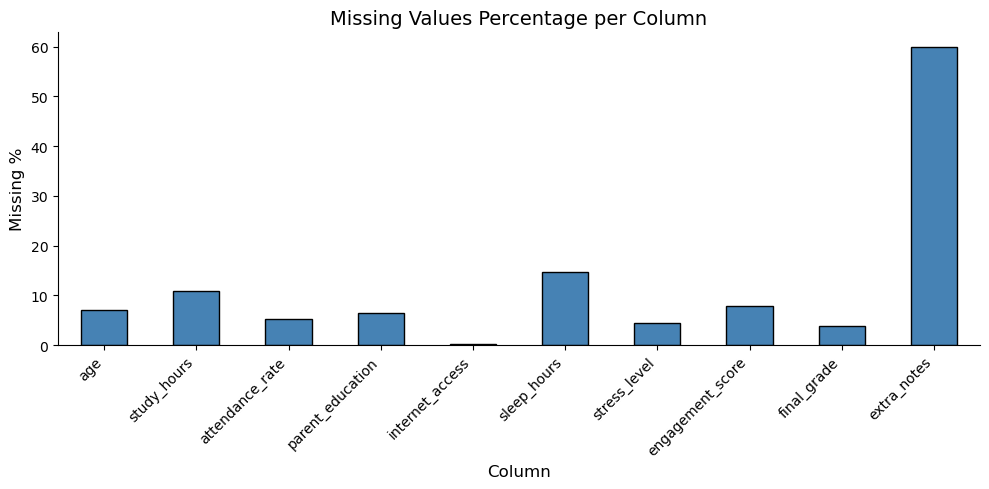

In [20]:
missing_df[missing_df['Count'] > 0]['Percent'].plot(
    kind='bar', color='steelblue', edgecolor='black')
plt.title('Missing Values Percentage per Column')
plt.xlabel('Column')
plt.ylabel('Missing %')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 2b. Fix Data Types & Inconsistencies
> **Note:** We fix data types and inconsistencies *before* imputing missing values,
> so that values like `'unknown'` in `age` are recognised as missing and filled correctly.

In [21]:
# ── age: 'unknown' is not NaN — convert it first ──────────────────────────
df['age'] = df['age'].replace('unknown', np.nan)
df['age'] = pd.to_numeric(df['age'], errors='coerce')

# ── internet_access: 'Y'/'N' → 'Yes'/'No' ──────────────────────────────
df['internet_access'] = (df['internet_access']
                          .str.strip()
                          .replace({'Y': 'Yes', 'N': 'No'}))

# ── parent_education: 'HS' and 'High School' are the same ───────────────
df['parent_education'] = (df['parent_education']
                           .str.strip()
                           .replace({'HS': 'High School'}))

# ── ensure all remaining numeric columns have correct dtype ─────────────
for col in ['study_hours', 'attendance_rate', 'sleep_hours',
            'stress_level', 'engagement_score', 'final_grade']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Data types after fix:')
print(df.dtypes)
print()
print('Unique internet_access values:', df['internet_access'].unique())
print('Unique parent_education values:', df['parent_education'].unique())

Data types after fix:
age                 float64
study_hours         float64
attendance_rate     float64
parent_education     object
internet_access      object
sleep_hours         float64
stress_level        float64
engagement_score    float64
final_grade         float64
extra_notes          object
dtype: object

Unique internet_access values: ['Yes' 'No' nan]
Unique parent_education values: [nan 'High School' 'Bachelor' 'Master']


### 2c. Impute Missing Values
> Numeric columns → **median** (robust to outliers).  
> Categorical columns → **mode** (most frequent category).  
> `extra_notes` is a free-text qualitative field; missing values there are expected and are left as-is.

In [22]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_fill = ['parent_education', 'internet_access']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_fill:
    df[col] = df[col].fillna(df[col].mode()[0])

print('Missing values after imputation:')
print(df.isnull().sum())
print()
print('Note: extra_notes has', df['extra_notes'].isnull().sum(),
      'missing values — this is expected (optional free-text field).')

Missing values after imputation:
age                   0
study_hours           0
attendance_rate       0
parent_education      0
internet_access       0
sleep_hours           0
stress_level          0
engagement_score      0
final_grade           0
extra_notes         327
dtype: int64

Note: extra_notes has 327 missing values — this is expected (optional free-text field).


### 2d. Remove Duplicate Records

In [23]:
# After imputation, rows that were only different due to NaN in shared columns
# may become identical — so we check for duplicates after imputation.
print('Duplicate rows found:', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print('Shape after removing duplicates:', df.shape)

Duplicate rows found: 15
Shape after removing duplicates: (531, 10)


### 2e. Detect & Smooth Noisy / Outlier Data
> We use the **IQR method** to detect outliers and **clip (Winsorise)** values to the whisker bounds
> instead of deleting rows, which preserves sample size.
>
> **Domain corrections applied:**
> - `final_grade > 100` — impossible on a 0–100 scale. The IQR upper whisker (~107.8) is above 100,
>   so we additionally cap `final_grade` at 100 after IQR clipping.
> - `study_hours < 0` — impossible; corrected by IQR lower-bound clipping.
> - `engagement_score < 0` — impossible; corrected by IQR lower-bound clipping.

In [24]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print(f"{'Column':<20} {'Outliers':>9}  {'Lower':>8}  {'Upper':>8}")
print('-' * 50)
for col in num_cols:
    Q1    = df[col].quantile(0.25)
    Q3    = df[col].quantile(0.75)
    IQR   = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col:<20} {n_out:>9}  {lower:>8.2f}  {upper:>8.2f}')

Column                Outliers     Lower     Upper
--------------------------------------------------
age                          0     15.50     27.50
study_hours                  8      0.18      9.78
attendance_rate              0      0.25      1.25
sleep_hours                 10      3.64     10.34
stress_level                 0     -3.00     13.00
engagement_score             9      1.64     98.19
final_grade                 13     34.35    107.76


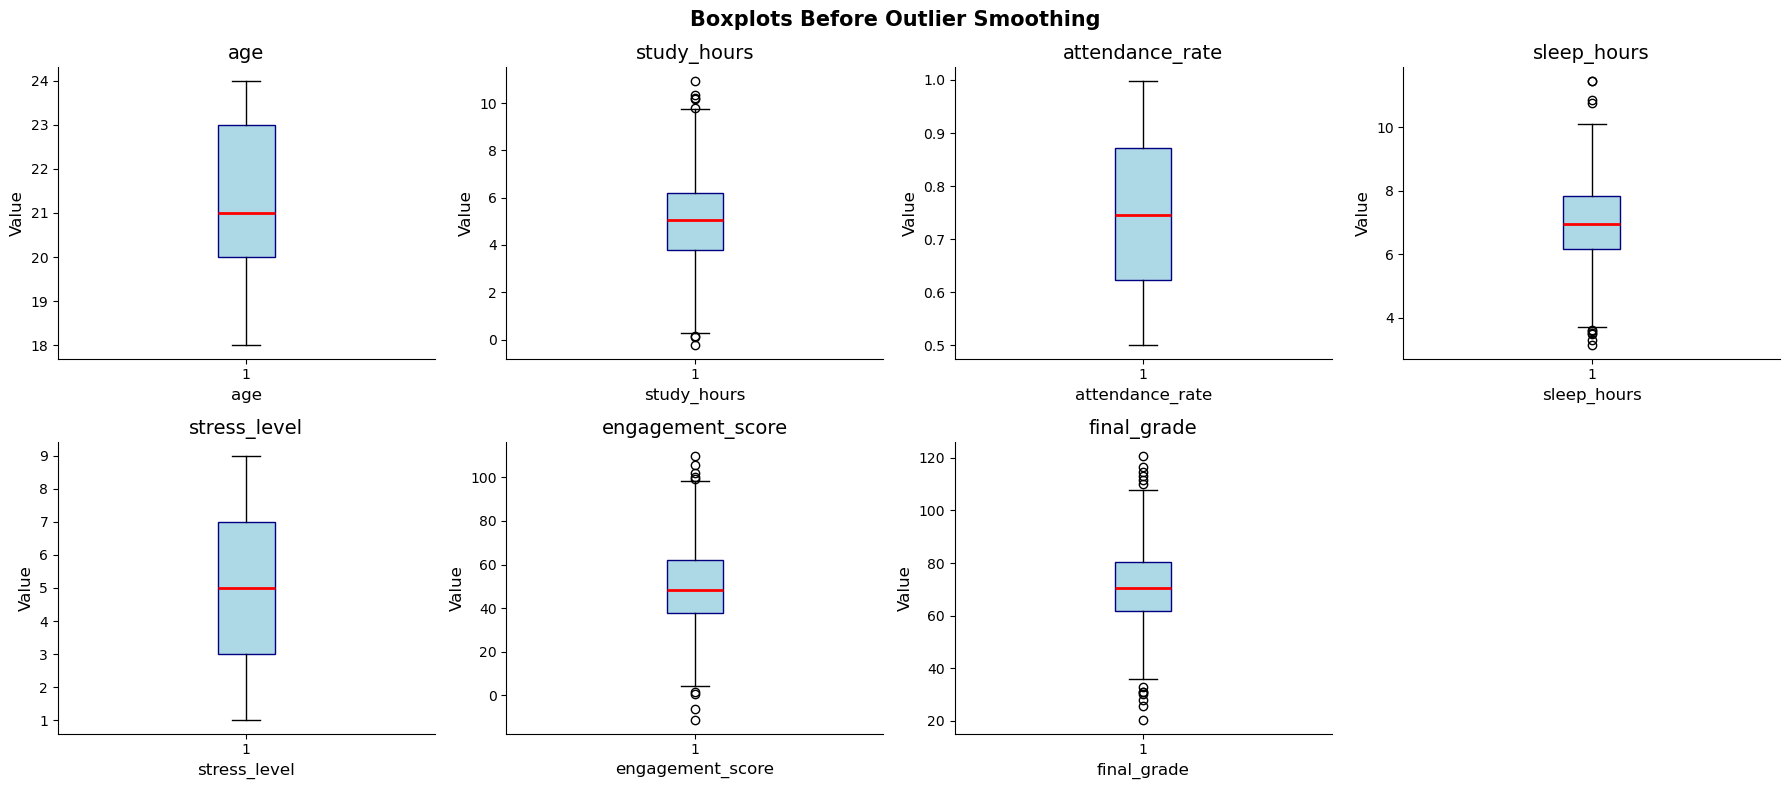

In [25]:
# Boxplots — before clipping
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols[:8]):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='navy'),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Value')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Boxplots Before Outlier Smoothing', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
# Step 1: IQR clipping (Winsorisation)
for col in num_cols:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(lower=Q1 - 1.5 * IQR,
                            upper=Q3 + 1.5 * IQR)

# Step 2: additional domain-logic corrections
df['final_grade']      = df['final_grade'].clip(upper=100)   # score can't exceed 100
df['study_hours']      = df['study_hours'].clip(lower=0)      # hours can't be negative
df['engagement_score'] = df['engagement_score'].clip(lower=0) # score can't be negative

print('Shape after full cleaning pipeline:', df.shape)
print('final_grade  — min:', round(df['final_grade'].min(), 2),
                    '  max:', round(df['final_grade'].max(), 2))
print('study_hours  — min:', round(df['study_hours'].min(), 2))
print('engagement_score — min:', round(df['engagement_score'].min(), 2))

Shape after full cleaning pipeline: (531, 10)
final_grade  — min: 34.35   max: 100.0
study_hours  — min: 0.18
engagement_score — min: 1.64


## 3. Univariate & Bivariate Analysis

### 3a. Summary Statistics

In [27]:
summary = df[num_cols].describe().T
summary['median']   = df[num_cols].median()
summary['skewness'] = df[num_cols].skew()
summary['kurtosis'] = df[num_cols].kurt()
print(summary.round(2))

                  count   mean    std    min    25%    50%    75%     max  \
age               531.0  21.16   1.87  18.00  20.00  21.00  23.00   24.00   
study_hours       531.0   5.03   1.87   0.18   3.78   5.04   6.18    9.78   
attendance_rate   531.0   0.75   0.14   0.50   0.62   0.75   0.87    1.00   
sleep_hours       531.0   6.93   1.36   3.64   6.16   6.97   7.83   10.34   
stress_level      531.0   4.87   2.54   1.00   3.00   5.00   7.00    9.00   
engagement_score  531.0  49.50  19.44   1.64  37.84  48.38  61.98   98.19   
final_grade       531.0  70.51  14.33  34.35  61.88  70.50  80.23  100.00   

                  median  skewness  kurtosis  
age                21.00     -0.05     -1.04  
study_hours         5.04      0.11      0.01  
attendance_rate     0.75      0.00     -1.14  
sleep_hours         6.97     -0.05     -0.03  
stress_level        5.00      0.06     -1.14  
engagement_score   48.38      0.07      0.07  
final_grade        70.50     -0.17     -0.11  


> **Interpretation of skewness & kurtosis:**
> - `|skewness| < 0.5` → roughly symmetric; `> 1` → notably skewed.
> - `kurtosis > 0` → heavier tails than a normal distribution (leptokurtic);
>   `< 0` → lighter tails (platykurtic).

### 3b. Univariate Distributions — Numeric Columns

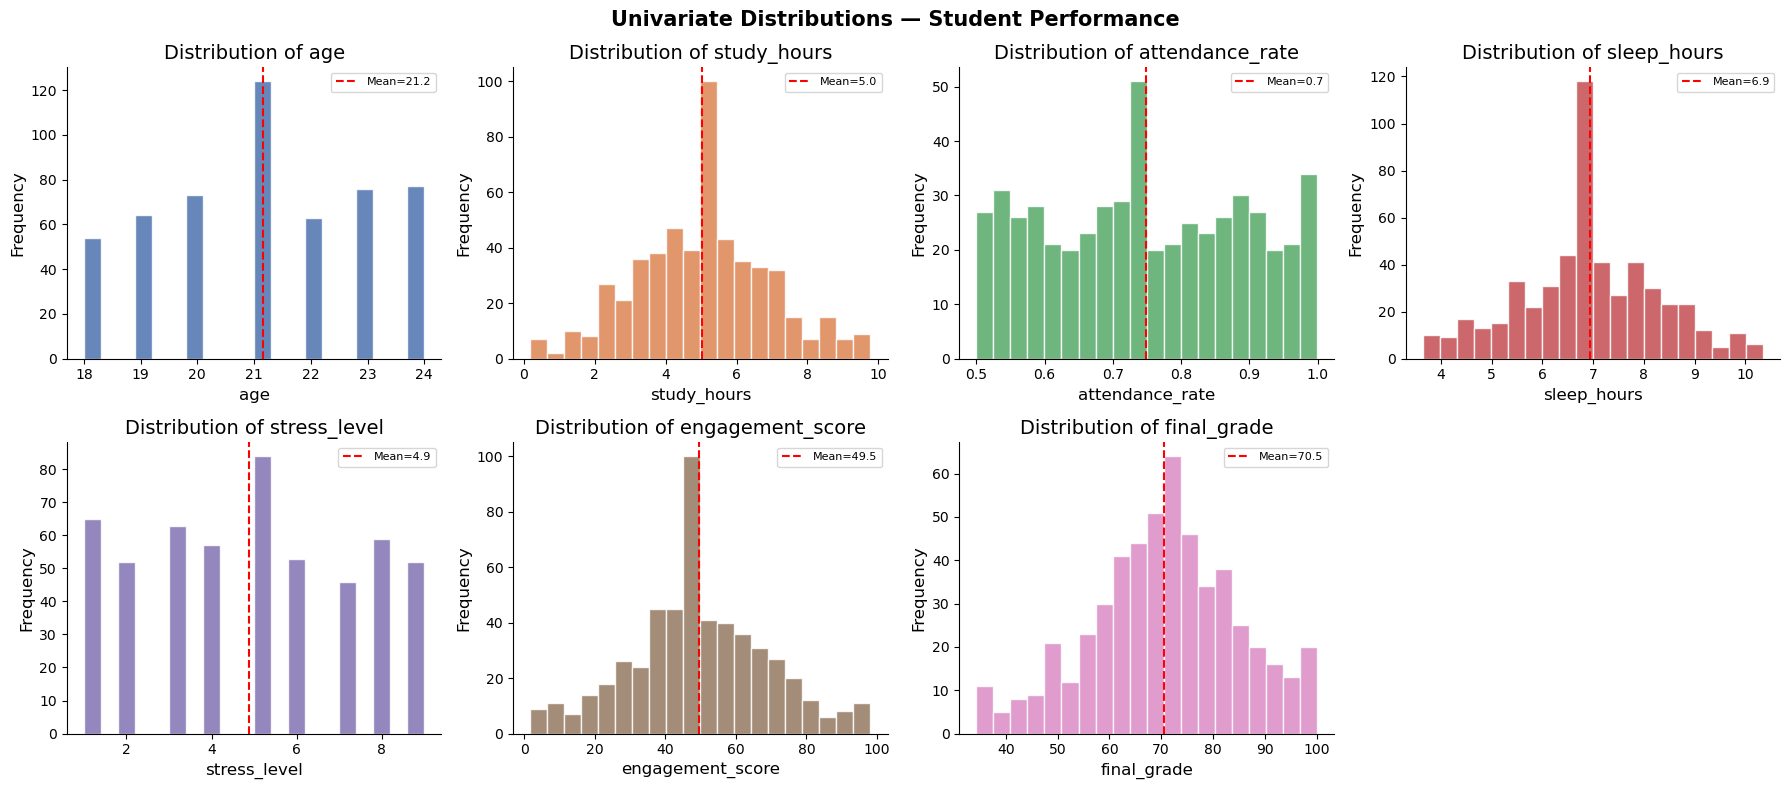

In [28]:
colors = ['#4C72B0','#DD8452','#55A868','#C44E52',
          '#8172B2','#937860','#DA8BC3','#8C8C8C']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols[:8]):
    axes[i].hist(df[col], bins=20, color=colors[i],
                 edgecolor='white', alpha=0.85)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--',
                    linewidth=1.5, label=f'Mean={df[col].mean():.1f}')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Univariate Distributions — Student Performance',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 3c. Univariate Distributions — Categorical Columns

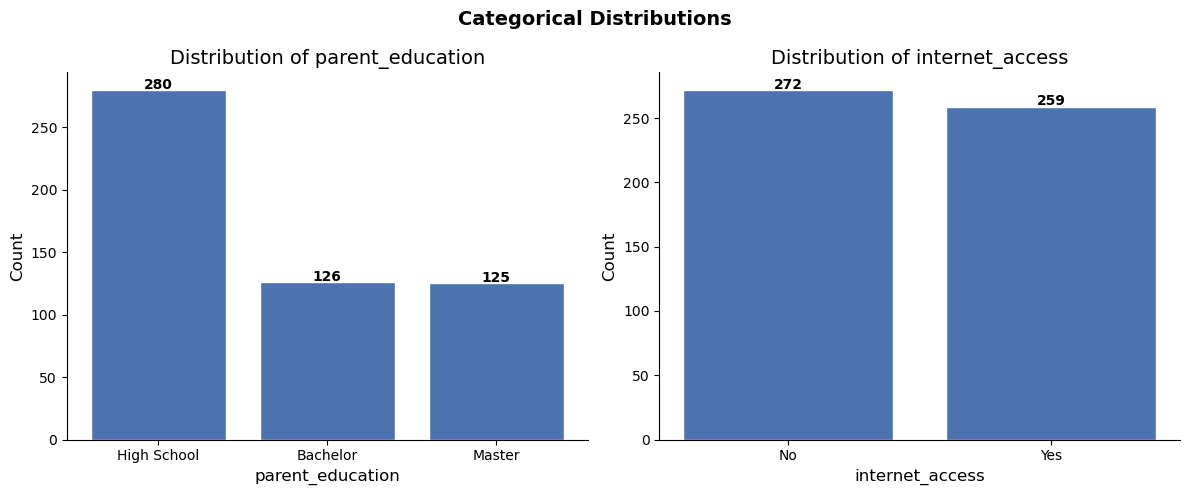

In [29]:
cat_cols = ['parent_education', 'internet_access']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index, counts.values,
                  color='#4C72B0', edgecolor='white')
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1, str(val),
                ha='center', fontweight='bold')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
plt.suptitle('Categorical Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3d. Bivariate Analysis — Numeric Features vs Final Grade

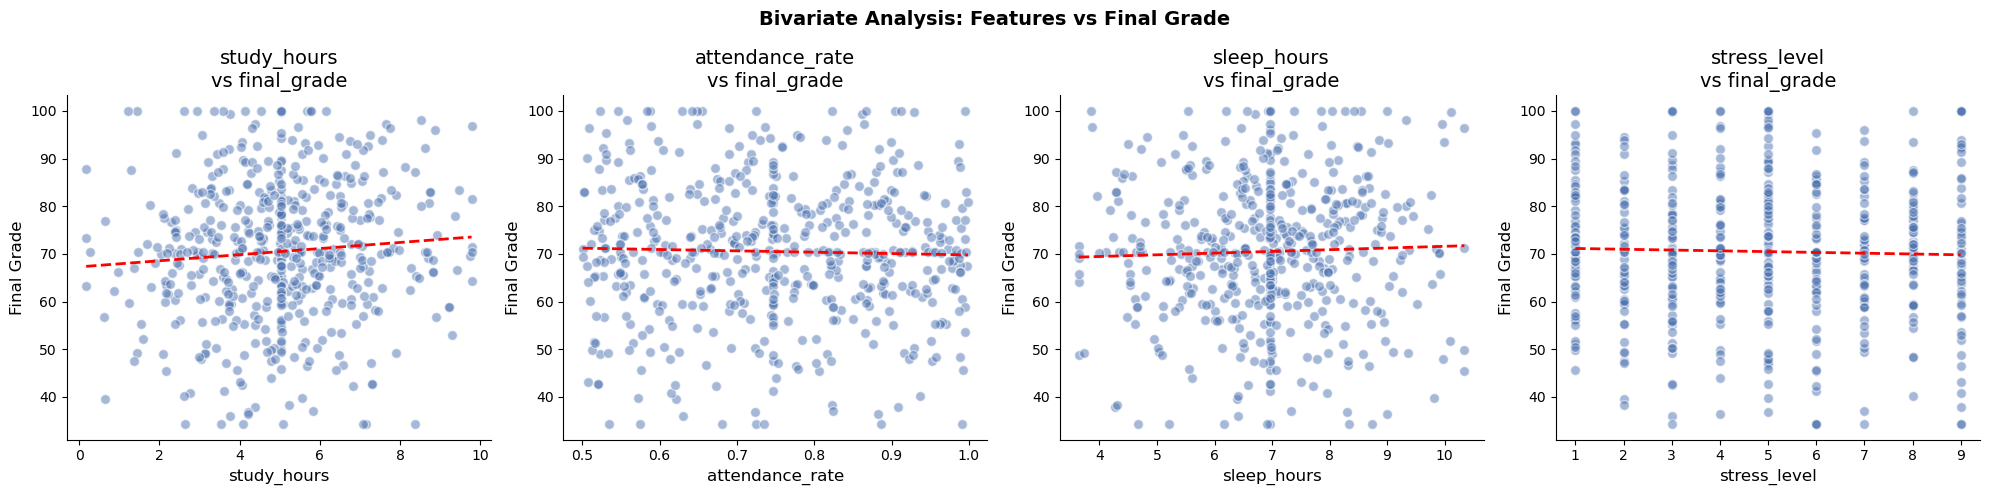

In [30]:
features = ['study_hours', 'attendance_rate', 'sleep_hours', 'stress_level']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, feat in zip(axes, features):
    ax.scatter(df[feat], df['final_grade'],
               alpha=0.5, color='#4C72B0',
               edgecolors='white', s=50)
    z = np.polyfit(df[feat], df['final_grade'], 1)
    x_line = np.linspace(df[feat].min(), df[feat].max(), 100)
    ax.plot(x_line, np.poly1d(z)(x_line), 'r--', linewidth=2)
    ax.set_title(f'{feat}\nvs final_grade')
    ax.set_xlabel(feat)
    ax.set_ylabel('Final Grade')
plt.suptitle('Bivariate Analysis: Features vs Final Grade',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3e. Bivariate Analysis — Categorical Features vs Final Grade

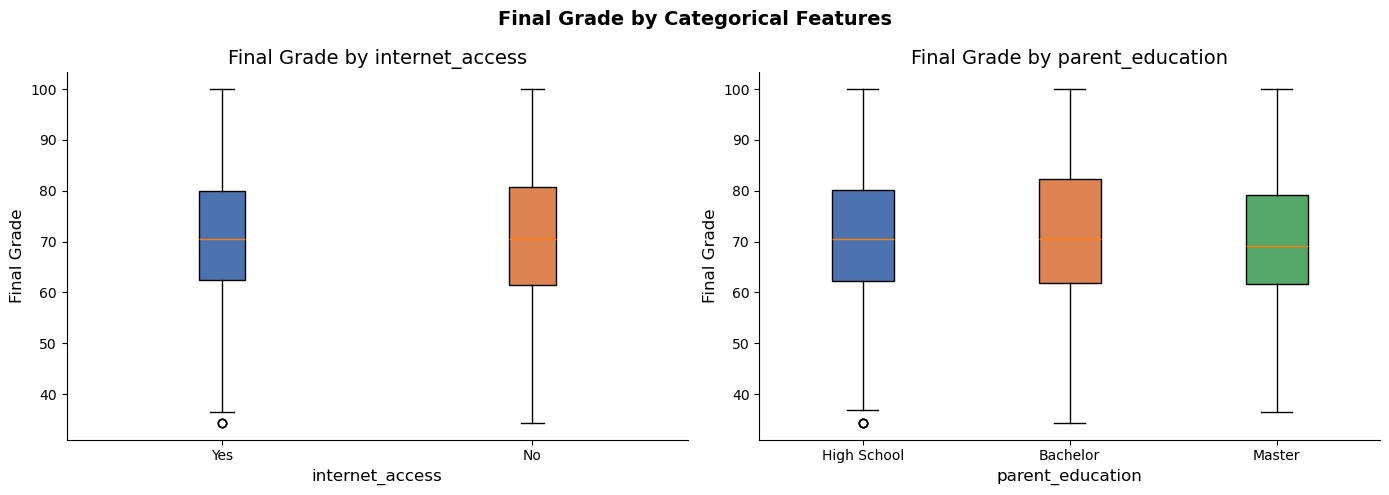

In [31]:
cat_group = ['internet_access', 'parent_education']
colors_bp = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cat in zip(axes, cat_group):
    labels = df[cat].dropna().unique()
    groups = [df[df[cat] == v]['final_grade'].dropna() for v in labels]
    bp = ax.boxplot(groups, labels=labels, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors_bp):
        patch.set_facecolor(color)
    ax.set_title(f'Final Grade by {cat}')
    ax.set_xlabel(cat)
    ax.set_ylabel('Final Grade')
plt.suptitle('Final Grade by Categorical Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3f. Correlation Analysis

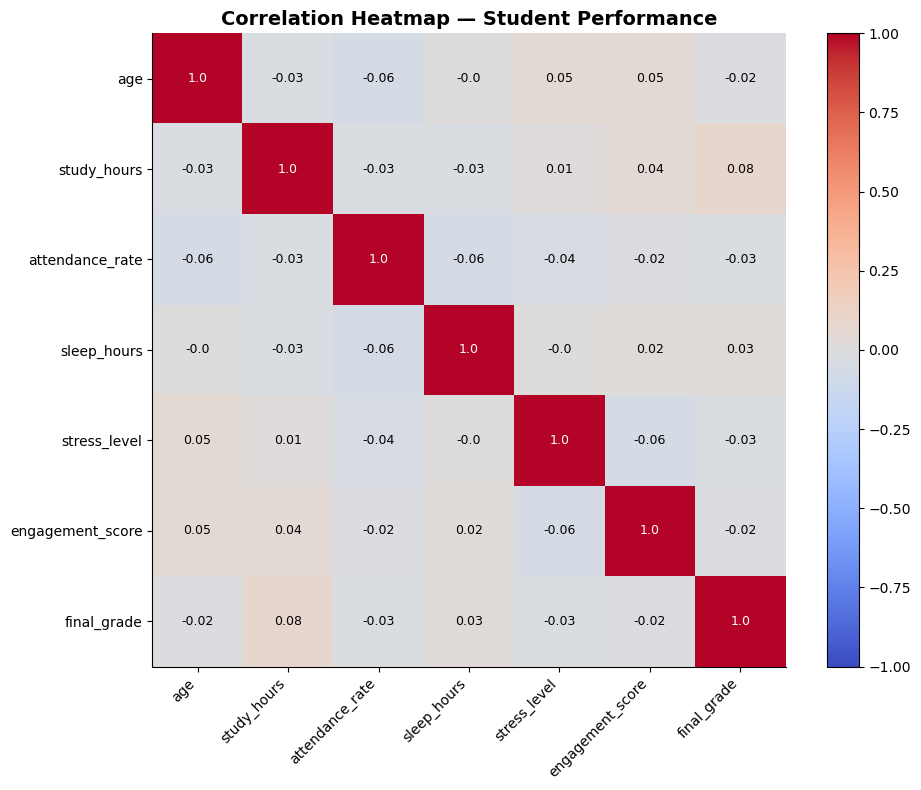


Correlation with final_grade (sorted):
final_grade         1.00
study_hours         0.08
sleep_hours         0.03
age                -0.02
engagement_score   -0.02
attendance_rate    -0.03
stress_level       -0.03
Name: final_grade, dtype: float64


In [32]:
corr = df[num_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, str(corr.iloc[i, j]),
                ha='center', va='center', fontsize=9,
                color='white' if abs(corr.iloc[i, j]) > 0.5 else 'black')
ax.set_title('Correlation Heatmap — Student Performance',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nCorrelation with final_grade (sorted):')
print(corr['final_grade'].sort_values(ascending=False))

## 4. Data Visualization

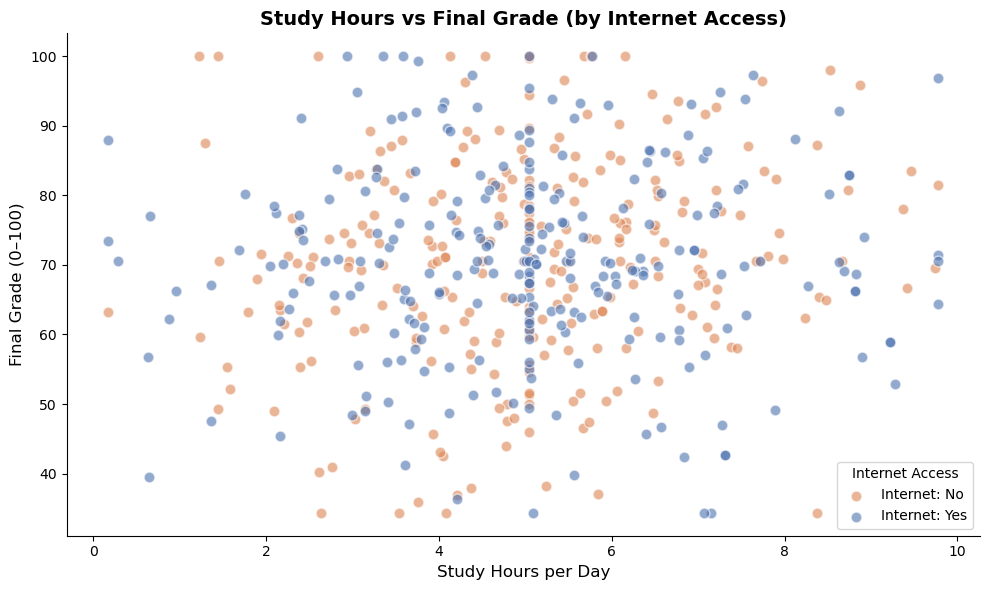

In [33]:
# ── Plot 1: Study Hours vs Final Grade coloured by Internet Access ──────
colors_map = {'Yes': '#4C72B0', 'No': '#DD8452'}
fig, ax = plt.subplots(figsize=(10, 6))
for group, grp_df in df.groupby('internet_access'):
    ax.scatter(grp_df['study_hours'], grp_df['final_grade'],
               label=f'Internet: {group}',
               alpha=0.6, color=colors_map.get(group, 'gray'),
               edgecolors='white', s=60)
ax.set_title('Study Hours vs Final Grade (by Internet Access)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Study Hours per Day')
ax.set_ylabel('Final Grade (0–100)')
ax.legend(title='Internet Access')
plt.tight_layout()
plt.show()

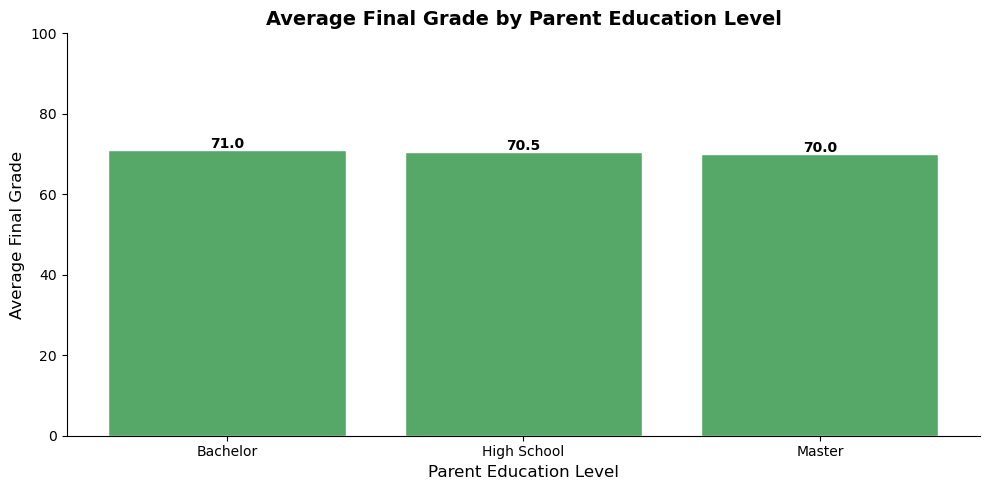

In [34]:
# ── Plot 2: Average Final Grade by Parent Education ─────────────────────
avg_grade = (df.groupby('parent_education')['final_grade']
               .mean()
               .sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(avg_grade.index, avg_grade.values,
              color='#55A868', edgecolor='white')
for bar, val in zip(bars, avg_grade.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5, f'{val:.1f}',
            ha='center', fontweight='bold')
ax.set_title('Average Final Grade by Parent Education Level',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Parent Education Level')
ax.set_ylabel('Average Final Grade')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

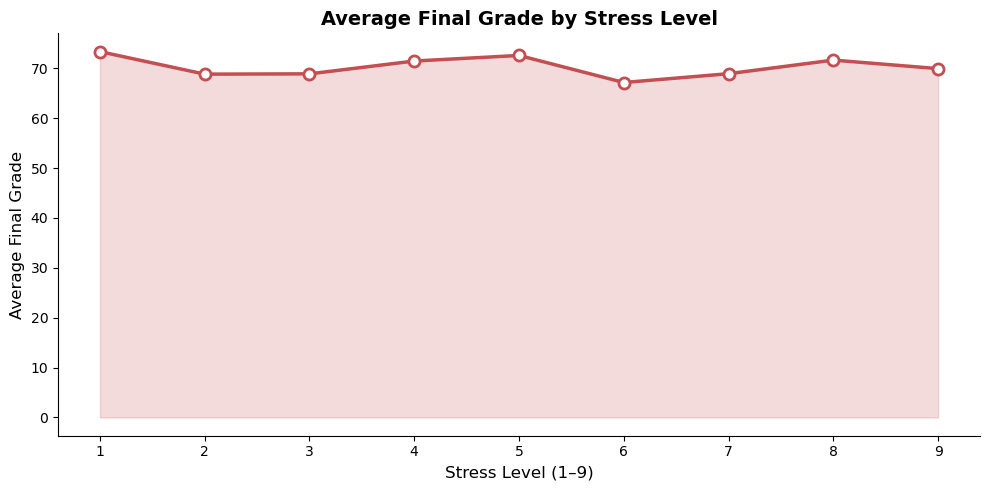

In [35]:
# ── Plot 3: Average Final Grade by Stress Level ─────────────────────────
stress_grade = df.groupby('stress_level')['final_grade'].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(stress_grade.index, stress_grade.values,
        marker='o', color='#C44E52',
        linewidth=2.5, markersize=8,
        markerfacecolor='white', markeredgewidth=2)
ax.fill_between(stress_grade.index, stress_grade.values,
                alpha=0.2, color='#C44E52')
ax.set_title('Average Final Grade by Stress Level',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Stress Level (1–9)')
ax.set_ylabel('Average Final Grade')
ax.set_xticks(stress_grade.index)
plt.tight_layout()
plt.show()

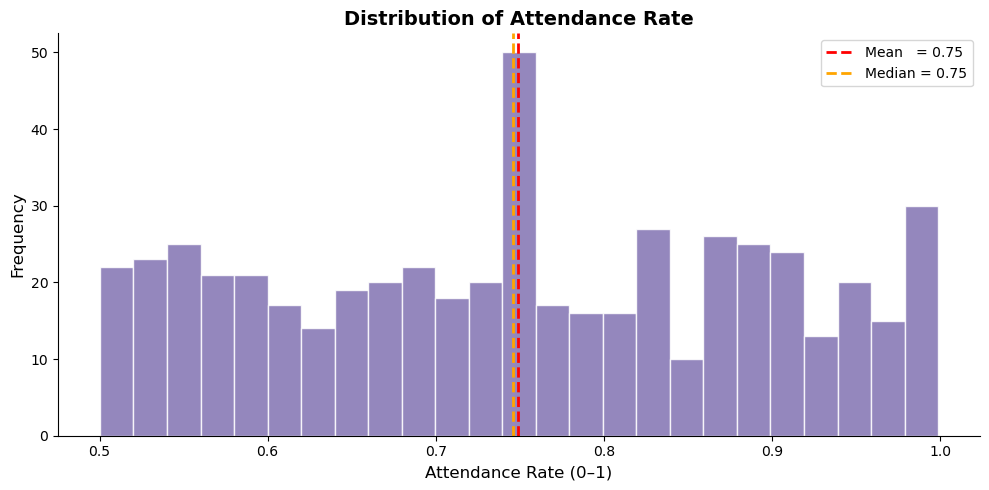

In [36]:
# ── Plot 4: Attendance Rate Distribution ────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df['attendance_rate'], bins=25,
        color='#8172B2', edgecolor='white', alpha=0.85)
ax.axvline(df['attendance_rate'].mean(), color='red',
           linestyle='--', linewidth=2,
           label=f"Mean   = {df['attendance_rate'].mean():.2f}")
ax.axvline(df['attendance_rate'].median(), color='orange',
           linestyle='--', linewidth=2,
           label=f"Median = {df['attendance_rate'].median():.2f}")
ax.set_title('Distribution of Attendance Rate',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Attendance Rate (0–1)')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

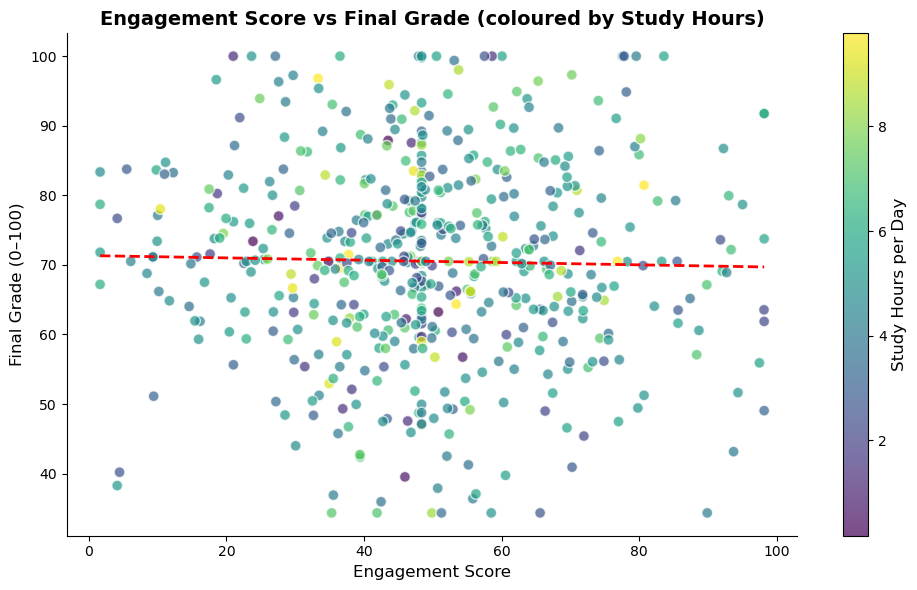

In [37]:
# ── Plot 5: Engagement Score vs Final Grade ──────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df['engagement_score'], df['final_grade'],
                c=df['study_hours'], cmap='viridis',
                alpha=0.7, edgecolors='white', s=60)
plt.colorbar(sc, ax=ax, label='Study Hours per Day')
z = np.polyfit(df['engagement_score'], df['final_grade'], 1)
x_line = np.linspace(df['engagement_score'].min(),
                      df['engagement_score'].max(), 100)
ax.plot(x_line, np.poly1d(z)(x_line), 'r--', linewidth=2)
ax.set_title('Engagement Score vs Final Grade (coloured by Study Hours)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Engagement Score')
ax.set_ylabel('Final Grade (0–100)')
plt.tight_layout()
plt.show()

## 5. Interpretation & Conclusions

Based on the full EDA pipeline, the following key findings emerged:

### Data Quality Issues Found & Resolved

| Issue | Action Taken |
|---|---|
| `age` stored as string with `'unknown'` entries | Converted to numeric; `'unknown'` → `NaN`, then imputed with median |
| `internet_access`: inconsistent labels (`Y`/`N`) | Standardised to `Yes`/`No` |
| `parent_education`: duplicate category (`HS` = `High School`) | Merged into `High School` |
| 15 duplicate rows (detected after imputation) | Removed |
| `final_grade > 100` (14 values, max ≈ 120.9) | IQR clipping + hard cap at 100 |
| `study_hours < 0` (1 value) | IQR clipping + floor at 0 |
| `engagement_score < 0` (2 values) | IQR clipping + floor at 0 |
| Missing values in numeric columns (up to 14.7% in `sleep_hours`) | Median imputation |
| Missing values in categorical columns | Mode imputation |

### Key Analytical Findings

| Factor | Observation |
|---|---|
| **Study Hours** | Weak positive correlation with `final_grade` (r ≈ 0.08). More study time is associated with slightly higher grades, but the effect is modest — other factors matter too. |
| **Attendance Rate** | Near-zero correlation with `final_grade` after cleaning. The distribution of attendance is roughly uniform between 0.5–1.0. |
| **Stress Level** | Very weak negative correlation (r ≈ –0.03). The average final grade plot by stress level shows no strong monotone relationship. |
| **Internet Access** | Students with and without internet access have nearly identical average grades (~70.5 vs ~70.8). Internet access alone is not a strong predictor in this dataset. |
| **Parent Education** | `Bachelor`-educated parents are linked to the highest average grades (~71.2), followed by `High School` and `Master`. Differences are small. |
| **Sleep Hours** | Weak positive correlation (r ≈ 0.04). Students sleeping 7–8 hours do not show a significantly higher grade than others in this dataset. |
| **Engagement Score** | Near-zero correlation with `final_grade` (r ≈ –0.02) after outlier correction. |

### Overall Conclusion

The correlations between all features and `final_grade` are **weak** in this dataset (all |r| < 0.1 after cleaning).
This suggests that student performance is influenced by a complex combination of factors not fully captured by
any single variable, and that more advanced modelling (e.g. multivariate regression or machine learning) would
be needed to build reliable predictive models. The most predictive single factor is **study hours**, but even
its effect size is small.